In [8]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer

from tensorflow import keras
from keras.layers import Dense, Input, Embedding, GlobalMaxPooling1D, MaxPooling1D
from keras.models import Model, Sequential
from keras.losses import SparseCategoricalCrossentropy

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

import warnings
warnings.filterwarnings('ignore')

## Text Classification using ANN

In [2]:
df = pd.read_csv('BBC_Text_CLS.csv')
df.head()

,text,labels
0,Ad sales boost Time Warner profit\n\nQuarterly...,business
1,Dollar gains on Greenspan speech\n\nThe dollar...,business
2,Yukos unit buyer faces loan claim\n\nThe owner...,business
3,High fuel prices hit BA's profits\n\nBritish A...,business
4,Pernod takeover talk lifts Domecq\n\nShares in...,business


In [3]:
df['labels'].value_counts()

labels
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64

In [4]:
df['targets'] = df['labels'].astype('category').cat.codes

In [5]:
# Number of classes
K = df['targets'].max() + 1
K

np.int8(5)

In [6]:
df.sample(5)

,text,labels,targets
451,McDonald's boss Bell dies aged 44\n\nCharlie B...,business,0
513,Richard and Judy choose top books\n\nThe 10 au...,entertainment,1
1978,Games win for Blu-ray DVD format\n\nThe next-g...,tech,4
0,Ad sales boost Time Warner profit\n\nQuarterly...,business,0
1221,"Prime minister's questions\n\nSo who, if anyon...",politics,2


## Dataset Split

In [7]:
df_train, df_test = train_test_split(df, test_size=0.3, random_state=42)

In [12]:
tfidf = TfidfVectorizer(stop_words='english',max_features=10000)

X_train = tfidf.fit_transform(df_train['text'])
X_test = tfidf.transform(df_test['text'])

In [13]:
y_train = df_train['targets']
y_test = df_test['targets']

In [14]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1557, 10000), (668, 10000), (1557,), (668,))

In [ ]:
D = X_train.shape[1]   # Input dimension

## Model Building

In [16]:
model = Sequential([Input(shape=(D,)),

                    Dense(units=300, activation='relu'),
                    Dense(units=K)
                    ])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 300)            │     3,000,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,505 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,001,805 (11.45 MB)

 Trainable params: 3,001,805 (11.45 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(loss=SparseCategoricalCrossentropy(from_logits=True), 
              optimizer='adam', metrics=['accuracy'])

In [18]:
X_train = X_train.toarray()
X_test = X_test.toarray()

In [19]:
history = model.fit(
                    X_train, 
                    y_train,                    
                    validation_data=(X_test, y_test),
                    epochs=10, 
                    batch_size=128
                )

Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 85ms/step - accuracy: 0.8015 - loss: 1.4719 - val_accuracy: 0.9551 - val_loss: 1.2053
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.9872 - loss: 0.9444 - val_accuracy: 0.9686 - val_loss: 0.7306
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.9968 - loss: 0.4887 - val_accuracy: 0.9701 - val_loss: 0.4098
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.9981 - loss: 0.2306 - val_accuracy: 0.9716 - val_loss: 0.2530
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.9987 - loss: 0.1180 - val_accuracy: 0.9701 - val_loss: 0.1827
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 1.0000 - loss: 0.0691 - val_accuracy: 0.9760 - val_loss: 0.1481
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 1.0000 - loss: 0.0454 - val_accuracy: 0.9760 - val_loss: 0.1298
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 1.0000 - loss: 0.0326 - val_accuracy: 0.9790 - v

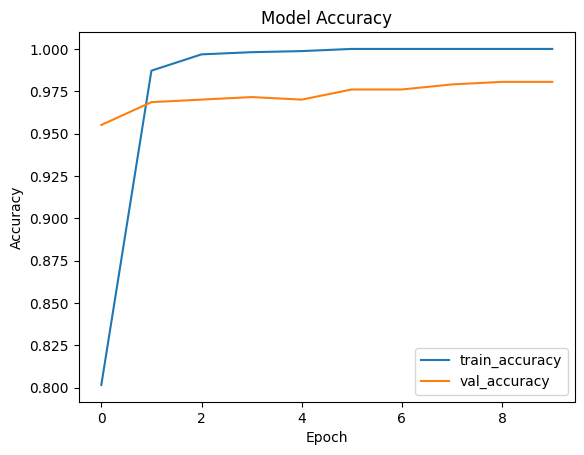

In [20]:
plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

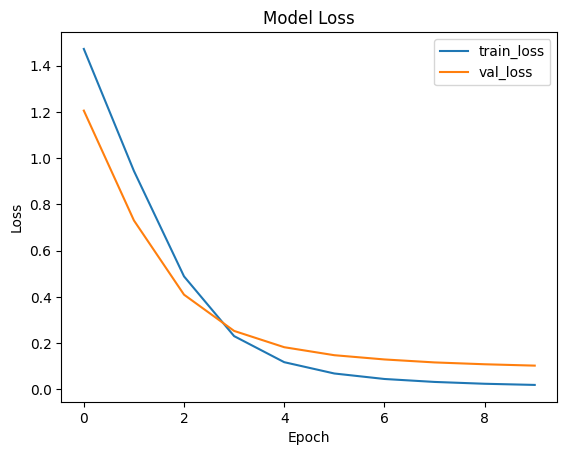

In [21]:
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label = 'val_loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [23]:
y_pred = model.predict(X_test).argmax(axis=1)

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [26]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.97      0.97       165
           1       0.99      0.99      0.99       118
           2       0.97      0.96      0.97       120
           3       0.99      0.99      0.99       140
           4       0.97      0.99      0.98       125

    accuracy                           0.98       668
   macro avg       0.98      0.98      0.98       668
weighted avg       0.98      0.98      0.98       668



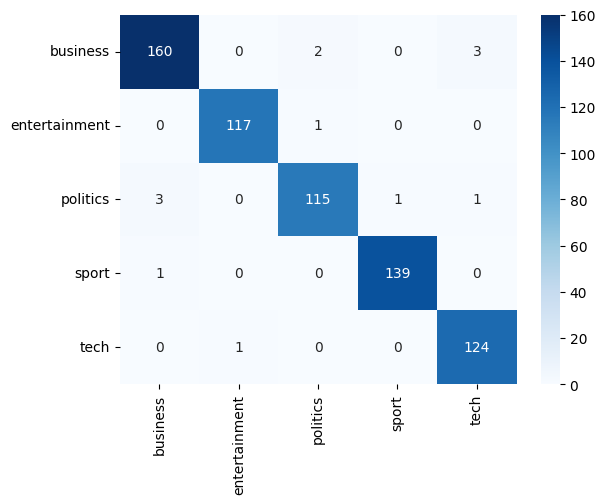

In [27]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=df['labels'].unique(), yticklabels=df['labels'].unique())
plt.show()